# Проверка MLP на задаче прогноза суточного потребления электроэнергии

**Постановка.** В файле почасовые данные (23 значения в сутках: часы 00–22). Задача: по предыдущим дням предсказать
профиль потребления **следующего дня целиком** (23 значения сразу) и сравнить с реальными данными.

**Схема проверки.**
1. Данные делятся по времени: последние 365 дней — тест, всё остальное — обучение (перемешивать нельзя).
2. MLP обучается на парах «день(дни) до → следующий день».
3. Для каждого тестового дня модель получает **реальные** данные предыдущих дней и предсказывает день вперёд.
4. Качество сравнивается с простыми базовыми прогнозами (вчера, неделю назад, плановое потребление).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ---------------- настройки ----------------
CSV_PATH   = 'combined.csv'
TARGET     = 'actual_consumption'    # что прогнозируем
PLAN_COL   = 'planned_consumption'   # плановое потребление (известно заранее)
LAG_DAYS   = 1                       # сколько предыдущих дней подаём на вход
TEST_DAYS  = 365                     # размер тестового периода
N_SEEDS    = 3                       # число MLP с разными инициализациями (усредняем)

## 1. Загрузка и очистка

In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=['date'], index_col='date').sort_index()

# Нули в этих столбцах - это пропуски измерений (их единицы: 6, 4 и 41 значение).
# Заменяем их на NaN и интерполируем по времени. Так портится только сама ячейка,
# а не вся строка.
df = df.replace(0, np.nan).interpolate(limit_direction='both')

print(df.shape, df.index.min(), '->', df.index.max())
print('NaN:', int(df.isna().sum().sum()))

(39721, 5) 2022-01-01 00:00:00 -> 2026-09-23 22:00:00
NaN: 0


## 2. Из почасовых строк в матрицу «день × час»

In [3]:
def to_day_matrix(series):
    g = series.groupby(series.index.date).apply(lambda x: x.values)
    days = pd.DatetimeIndex(g.index)
    return days, np.vstack(g.values)

days, ACTUAL = to_day_matrix(df[TARGET])
_,    PLAN   = to_day_matrix(df[PLAN_COL])

print('Матрица фактического потребления (дни x часы):', ACTUAL.shape)
assert ACTUAL.shape[1] == 23

Матрица фактического потребления (дни x часы): (1727, 23)


## 3. Признаки и целевая переменная

* **Вход:** потребление за предыдущие `LAG_DAYS` дней (23 × LAG_DAYS чисел) + календарь прогнозируемого дня
  (день недели, день года в виде sin/cos, флаг выходного).
  Вариант *с планом* дополнительно получает `planned_consumption` на прогнозируемый день (оно публикуется заранее).
* **Выход:** 23 значения потребления следующего дня.

In [4]:
def calendar_features(d):
    dow, doy = d.dayofweek, d.dayofyear
    return [np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7),
            np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25),
            float(dow >= 5)]

def make_dataset(lag, use_plan):
    X, Y, D = [], [], []
    for i in range(lag, len(days)):
        feats = [ACTUAL[i-lag:i].ravel(), calendar_features(days[i])]
        if use_plan:
            feats.append(PLAN[i])
        X.append(np.concatenate(feats))
        Y.append(ACTUAL[i])
        D.append(days[i])
    return np.array(X), np.array(Y), pd.DatetimeIndex(D)

def make_mlp(seed):
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3,
                         max_iter=1000, early_stopping=True,
                         validation_fraction=0.1, n_iter_no_change=30,
                         random_state=seed)),
        transformer=StandardScaler())   # масштабируем и целевые значения

def metrics(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = np.mean(np.abs(y_true - y_pred) / y_true) * 100
    return {'MAE': mae, 'RMSE': rmse, 'MAPE, %': mape}

## 4. Обучение MLP и прогноз на тестовый год

In [5]:
def run_mlp(lag, use_plan):
    X, Y, D = make_dataset(lag, use_plan)
    split = len(X) - TEST_DAYS
    X_tr, Y_tr = X[:split], Y[:split]
    X_te, Y_te = X[split:], Y[split:]

    preds = [make_mlp(s).fit(X_tr, Y_tr).predict(X_te) for s in range(N_SEEDS)]
    return Y_te, np.mean(preds, axis=0), D[split:]

y_true,  pred_noplan, test_days = run_mlp(LAG_DAYS, use_plan=False)
_,       pred_plan,   _         = run_mlp(LAG_DAYS, use_plan=True)

print('Тестовый период:', test_days.min().date(), '->', test_days.max().date(), f'({len(test_days)} дней)')

Тестовый период: 2025-09-24 -> 2026-09-23 (365 дней)


## 5. Сравнение с базовыми прогнозами

In [6]:
idx = np.array([days.get_loc(d) for d in test_days])

results = {
    'Базовый: вчерашний день':          metrics(y_true, ACTUAL[idx - 1]),
    'Базовый: тот же день неделю назад': metrics(y_true, ACTUAL[idx - 7]),
    'Плановое потребление (planned)':   metrics(y_true, PLAN[idx]),
    'MLP (по истории, без плана)':      metrics(y_true, pred_noplan),
    'MLP (история + planned)':          metrics(y_true, pred_plan),
}
table = pd.DataFrame(results).T.round(2)
table

,MAE,RMSE,"MAPE, %"
Базовый: вчерашний день,98.10,124.97,2.39
Базовый: тот же день неделю назад,134.91,170.29,3.26
Плановое потребление (planned),62.55,79.00,1.53
"MLP (по истории, без плана)",75.69,95.46,1.85
MLP (история + planned),56.03,70.60,1.38


## 6. Графики

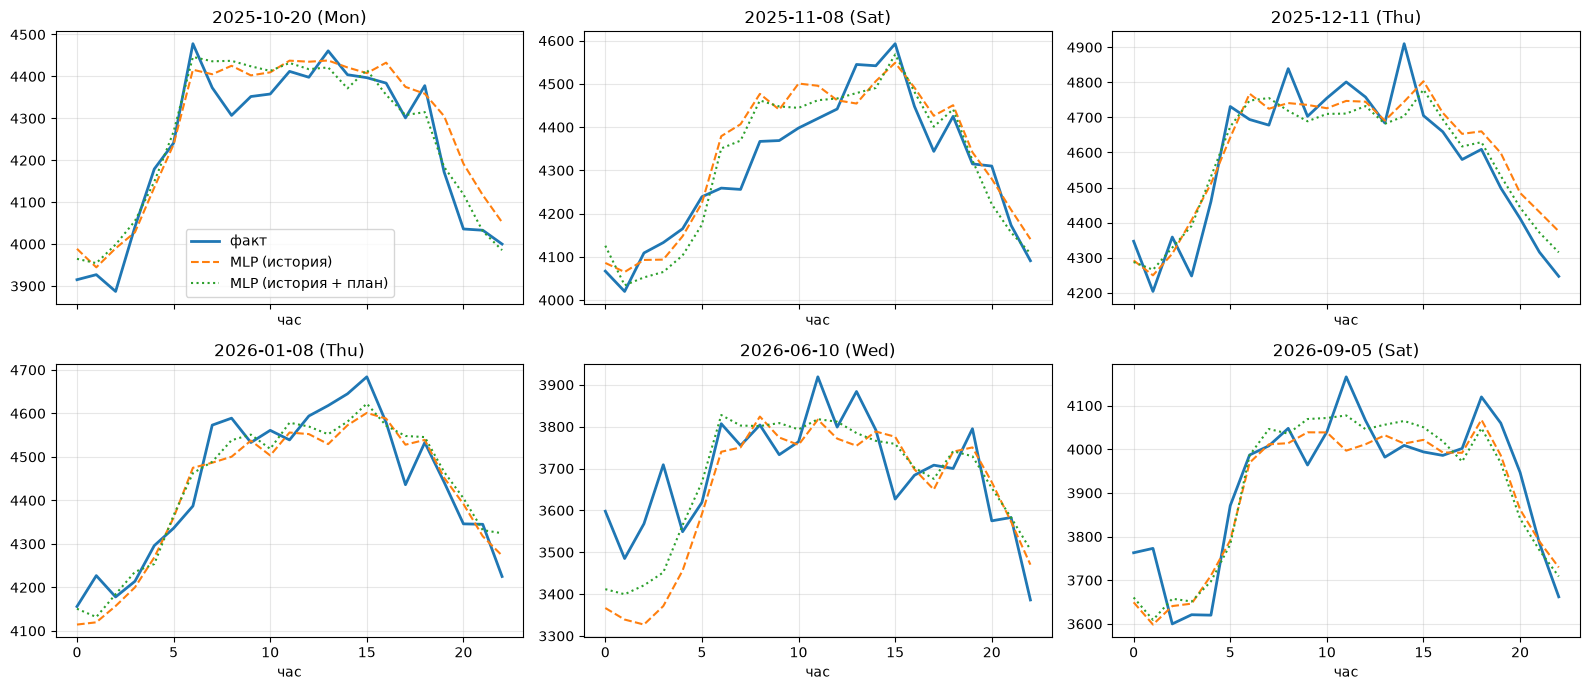

In [7]:
# 6.1 Несколько тестовых дней: факт и прогноз MLP по часам
rng = np.random.RandomState(0)
pick = np.sort(rng.choice(len(test_days), 6, replace=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for ax, k in zip(axes.ravel(), pick):
    ax.plot(y_true[k], label='факт', lw=2)
    ax.plot(pred_noplan[k], '--', label='MLP (история)')
    ax.plot(pred_plan[k], ':', label='MLP (история + план)')
    ax.set_title(test_days[k].strftime('%Y-%m-%d (%a)'))
    ax.set_xlabel('час'); ax.grid(alpha=.3)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

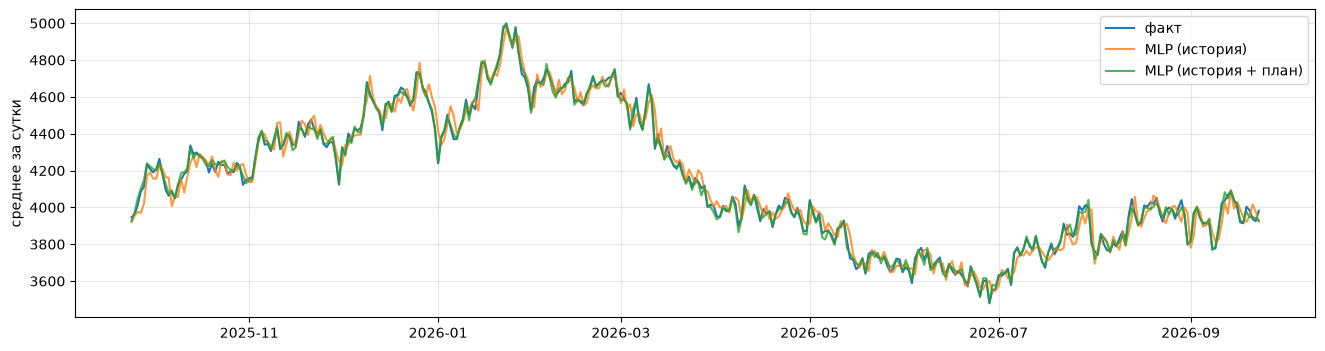

In [8]:
# 6.2 Весь тестовый год: среднесуточное потребление
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(test_days, y_true.mean(axis=1),       label='факт', lw=1.5)
ax.plot(test_days, pred_noplan.mean(axis=1),  label='MLP (история)', alpha=.8)
ax.plot(test_days, pred_plan.mean(axis=1),    label='MLP (история + план)', alpha=.8)
ax.set_ylabel('среднее за сутки'); ax.legend(); ax.grid(alpha=.3)
plt.show()

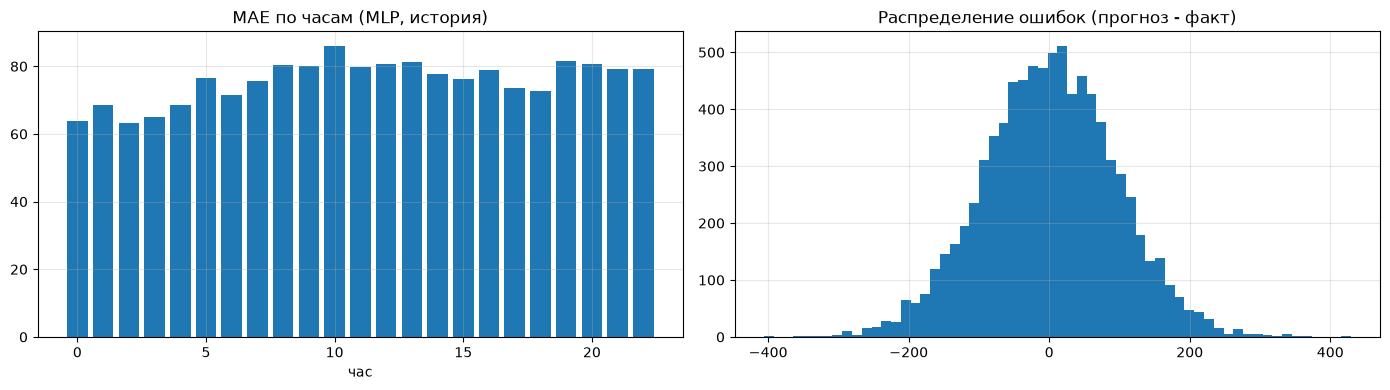

In [9]:
# 6.3 Ошибка по часам суток и распределение ошибок
hour_mae = np.abs(y_true - pred_noplan).mean(axis=0)
err = (pred_noplan - y_true).ravel()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(23), hour_mae); ax[0].set_title('MAE по часам (MLP, история)')
ax[0].set_xlabel('час'); ax[0].grid(alpha=.3)
ax[1].hist(err, bins=60); ax[1].set_title('Распределение ошибок (прогноз - факт)')
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Как читать результат

* Если MLP заметно лучше «вчера» и «неделю назад» — он действительно извлёк закономерности, а не просто повторяет вчерашний день.
* Сравнение с `planned_consumption` показывает, даёт ли модель что-то сверх планового прогноза оператора.
* Для итогового вывода смотрите на **MAPE** (относительная ошибка в %) и **MAE** (ошибка в тех же единицах, что и данные).

## 8. Май 2026 — графики и точность для презентации

Май 2026 целиком входит в тестовый период (модель его не видела при обучении).
Все рисунки дополнительно сохраняются в папку `figures_may/` в формате PNG.

In [10]:
import os
from sklearn.metrics import r2_score
os.makedirs('figures_may', exist_ok=True)

MONTH, YEAR = 5, 2026
mask = (test_days.month == MONTH) & (test_days.year == YEAR)
may_days = test_days[mask]
yt  = y_true[mask]
p_h = pred_noplan[mask]          # MLP по истории
p_hp = pred_plan[mask]           # MLP история + planned
idx_may = idx[mask]

baselines = {
    'Вчерашний день':          ACTUAL[idx_may - 1],
    'Неделю назад':            ACTUAL[idx_may - 7],
    'Плановое потребление':    PLAN[idx_may],
    'MLP (история)':           p_h,
    'MLP (история + план)':    p_hp,
}
may_table = pd.DataFrame({k: {**metrics(yt, v), 'R2': r2_score(yt.ravel(), v.ravel())}
                          for k, v in baselines.items()}).T.round(3)
may_table.to_csv('figures_may/may_metrics.csv')
print(f'Май {YEAR}: {len(may_days)} дней, {yt.size} почасовых значений')
may_table

Май 2026: 31 дней, 713 почасовых значений


,MAE,RMSE,"MAPE, %",R2
Вчерашний день,101.665,127.995,2.681,0.622
Неделю назад,118.501,151.160,3.167,0.473
Плановое потребление,66.899,83.319,1.771,0.840
MLP (история),77.003,97.588,2.031,0.780
MLP (история + план),60.773,76.228,1.610,0.866


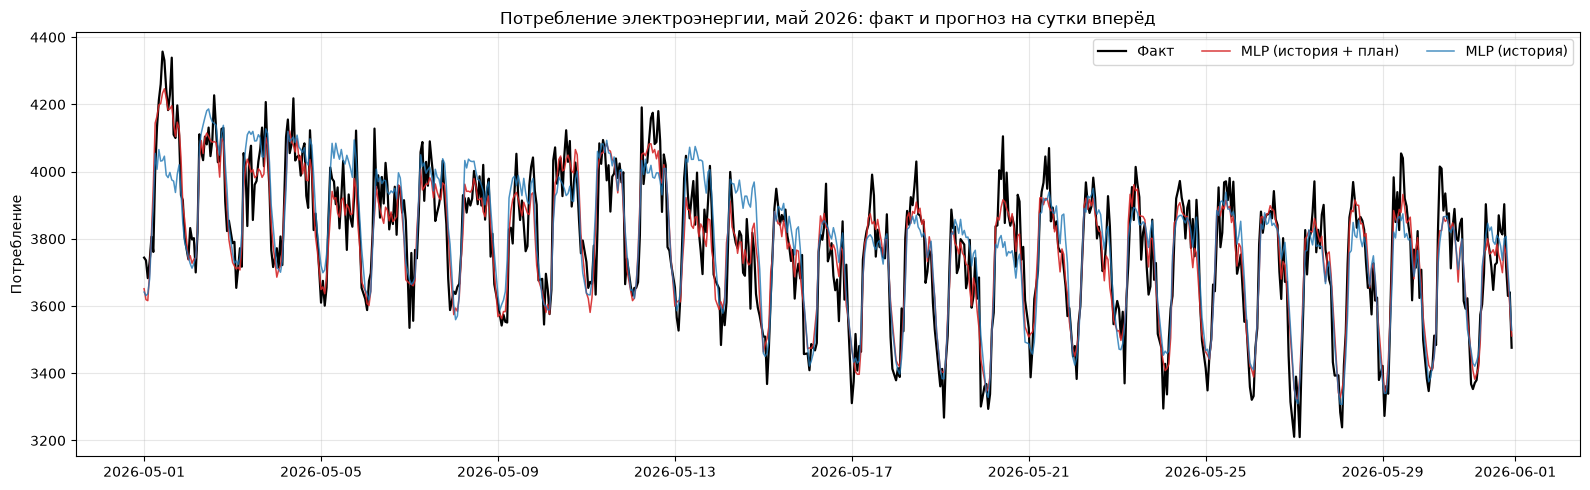

In [11]:
# Рис. 1. Весь май по часам: факт и прогноз MLP
hours_index = pd.DatetimeIndex([d + pd.Timedelta(hours=h) for d in may_days for h in range(23)])

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(hours_index, yt.ravel(),   color='black', lw=1.6, label='Факт')
ax.plot(hours_index, p_hp.ravel(), color='tab:red',  lw=1.1, alpha=.9, label='MLP (история + план)')
ax.plot(hours_index, p_h.ravel(),  color='tab:blue', lw=1.1, alpha=.8, label='MLP (история)')
ax.set_title(f'Потребление электроэнергии, май {YEAR}: факт и прогноз на сутки вперёд')
ax.set_ylabel('Потребление'); ax.grid(alpha=.3); ax.legend(ncol=3)
plt.tight_layout(); plt.savefig('figures_may/01_may_hourly.png', dpi=200); plt.show()

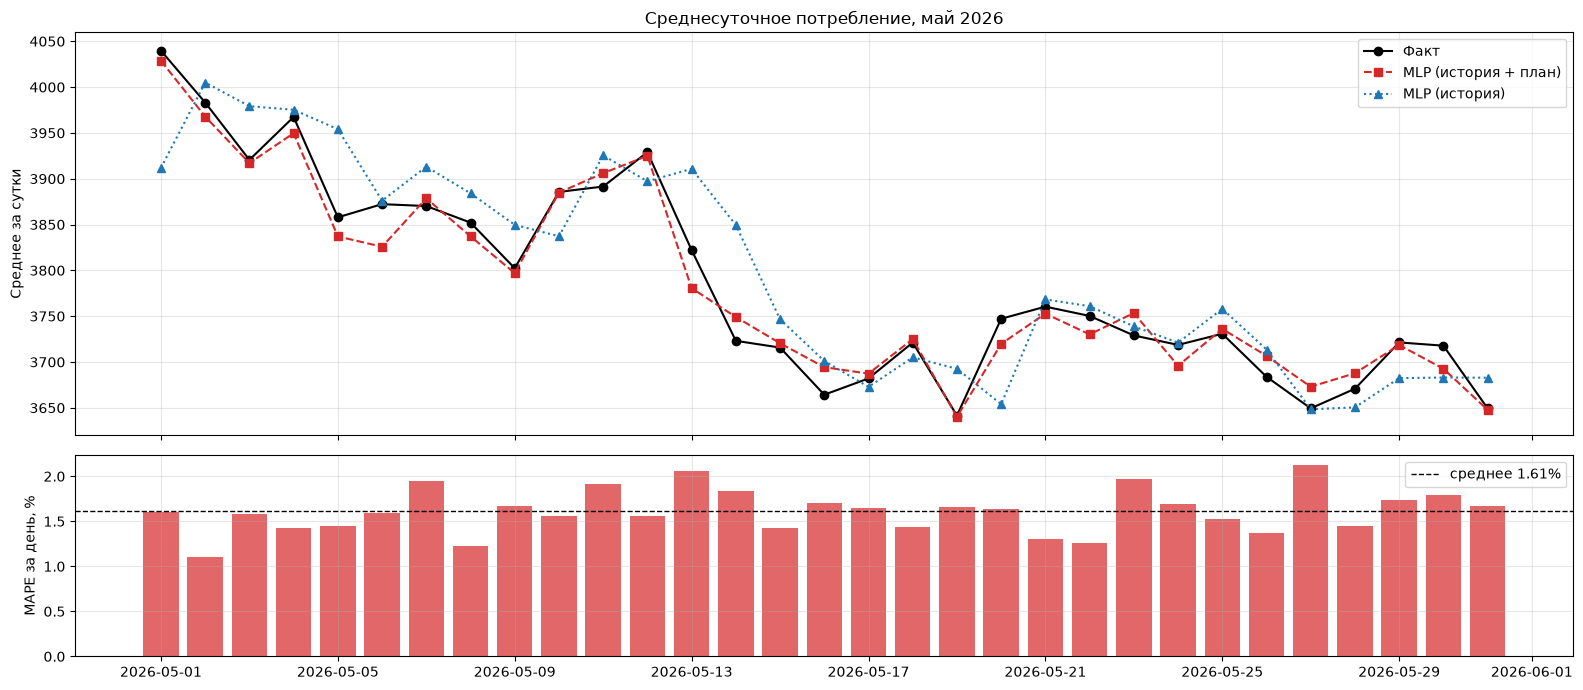

In [12]:
# Рис. 2. Среднесуточное потребление и дневная ошибка
daily_true = yt.mean(axis=1)
daily_mape = (np.abs(yt - p_hp) / yt).mean(axis=1) * 100

fig, ax = plt.subplots(2, 1, figsize=(16, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].plot(may_days, daily_true,       'o-', color='black',    label='Факт')
ax[0].plot(may_days, p_hp.mean(axis=1), 's--', color='tab:red', label='MLP (история + план)')
ax[0].plot(may_days, p_h.mean(axis=1),  '^:',  color='tab:blue', label='MLP (история)')
ax[0].set_ylabel('Среднее за сутки'); ax[0].grid(alpha=.3); ax[0].legend()
ax[0].set_title(f'Среднесуточное потребление, май {YEAR}')
ax[1].bar(may_days, daily_mape, color='tab:red', alpha=.7)
ax[1].axhline(daily_mape.mean(), color='k', ls='--', lw=1, label=f'среднее {daily_mape.mean():.2f}%')
ax[1].set_ylabel('MAPE за день, %'); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.savefig('figures_may/02_may_daily.png', dpi=200); plt.show()

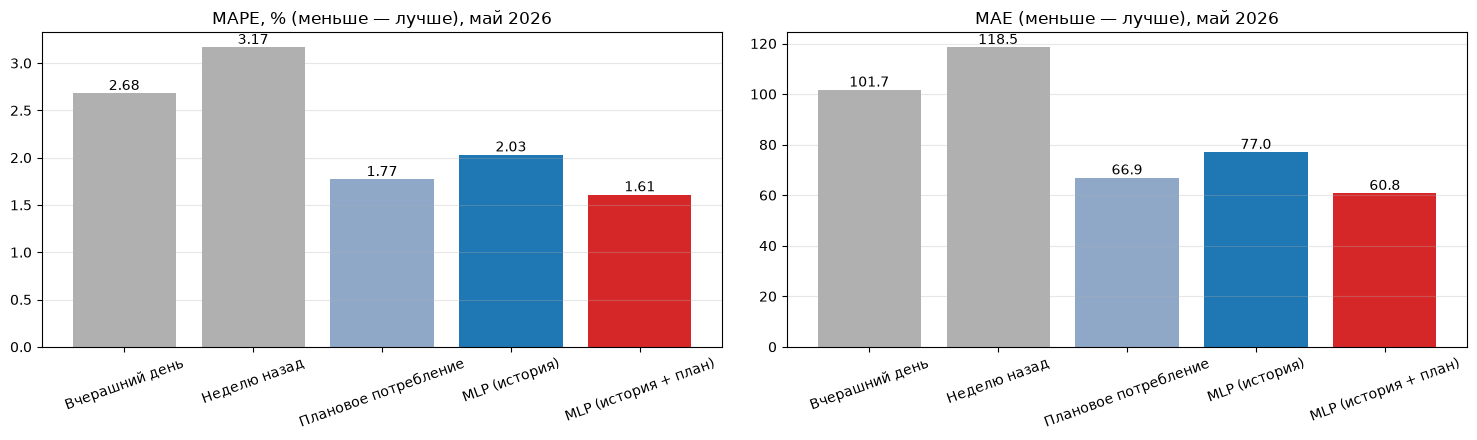

In [13]:
# Рис. 3. Сравнение методов по точности (MAPE и MAE)
order = list(may_table.index)
colors = ['#b0b0b0', '#b0b0b0', '#8fa8c8', 'tab:blue', 'tab:red']

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, col, ttl in zip(ax, ['MAPE, %', 'MAE'], ['MAPE, % (меньше — лучше)', 'MAE (меньше — лучше)']):
    bars = a.bar(order, may_table[col], color=colors)
    a.bar_label(bars, fmt='%.2f' if col.startswith('MAPE') else '%.1f')
    a.set_title(f'{ttl}, май {YEAR}'); a.tick_params(axis='x', rotation=20); a.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig('figures_may/03_may_methods.png', dpi=200); plt.show()

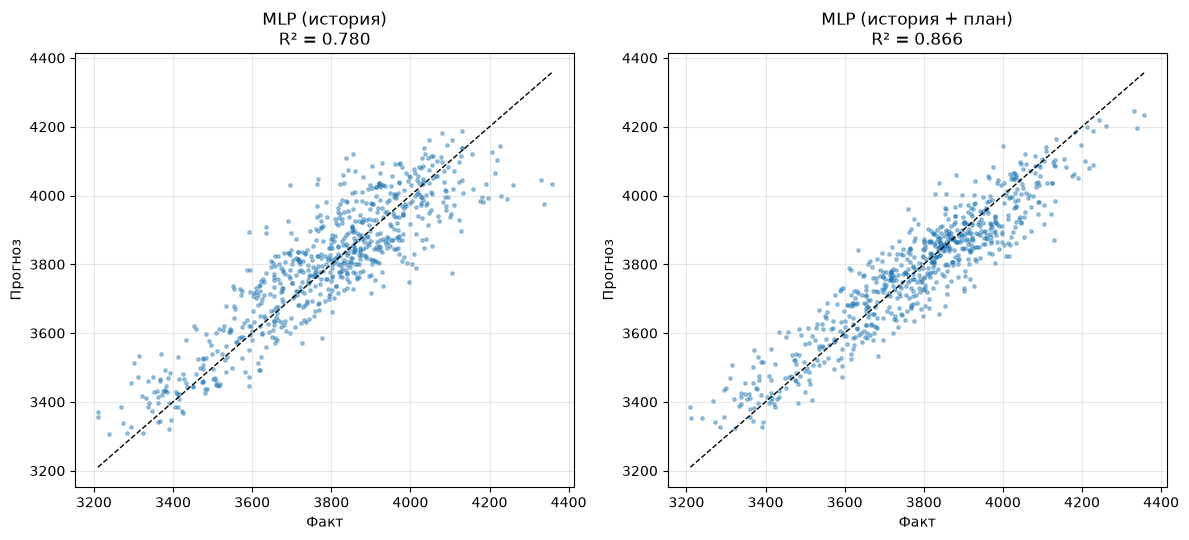

In [14]:
# Рис. 4. Факт против прогноза (идеальный прогноз лежит на диагонали)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
lo, hi = yt.min(), yt.max()
for a, p, ttl in zip(ax, [p_h, p_hp], ['MLP (история)', 'MLP (история + план)']):
    a.scatter(yt.ravel(), p.ravel(), s=6, alpha=.4)
    a.plot([lo, hi], [lo, hi], 'k--', lw=1)
    a.set_title(f'{ttl}\nR² = {r2_score(yt.ravel(), p.ravel()):.3f}')
    a.set_xlabel('Факт'); a.set_ylabel('Прогноз'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures_may/04_may_scatter.png', dpi=200); plt.show()

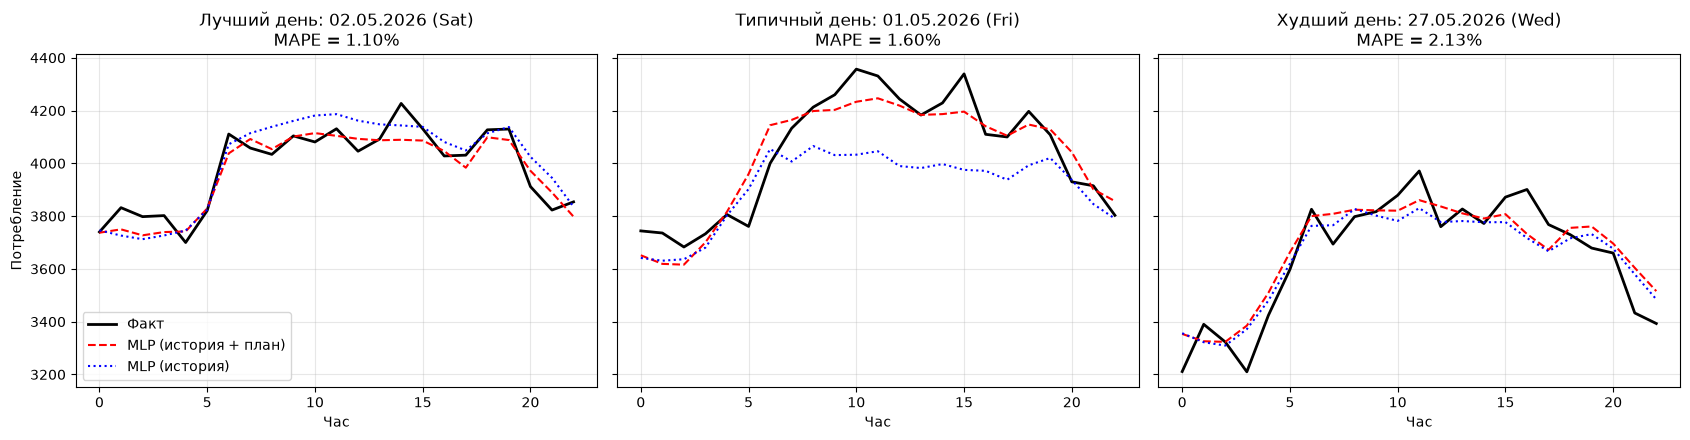

In [15]:
# Рис. 5. Лучший и худший день мая (по MAPE модели MLP история + план) и типичные дни
day_mape = (np.abs(yt - p_hp) / yt).mean(axis=1) * 100
best, worst = int(np.argmin(day_mape)), int(np.argmax(day_mape))
median = int(np.argsort(day_mape)[len(day_mape)//2])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for a, k, name in zip(axes, [best, median, worst], ['Лучший день', 'Типичный день', 'Худший день']):
    a.plot(yt[k], 'k-', lw=2, label='Факт')
    a.plot(p_hp[k], 'r--', label='MLP (история + план)')
    a.plot(p_h[k], 'b:', label='MLP (история)')
    a.set_title(f'{name}: {may_days[k]:%d.%m.%Y (%a)}\nMAPE = {day_mape[k]:.2f}%')
    a.set_xlabel('Час'); a.grid(alpha=.3)
axes[0].set_ylabel('Потребление'); axes[0].legend()
plt.tight_layout(); plt.savefig('figures_may/05_may_best_worst.png', dpi=200); plt.show()

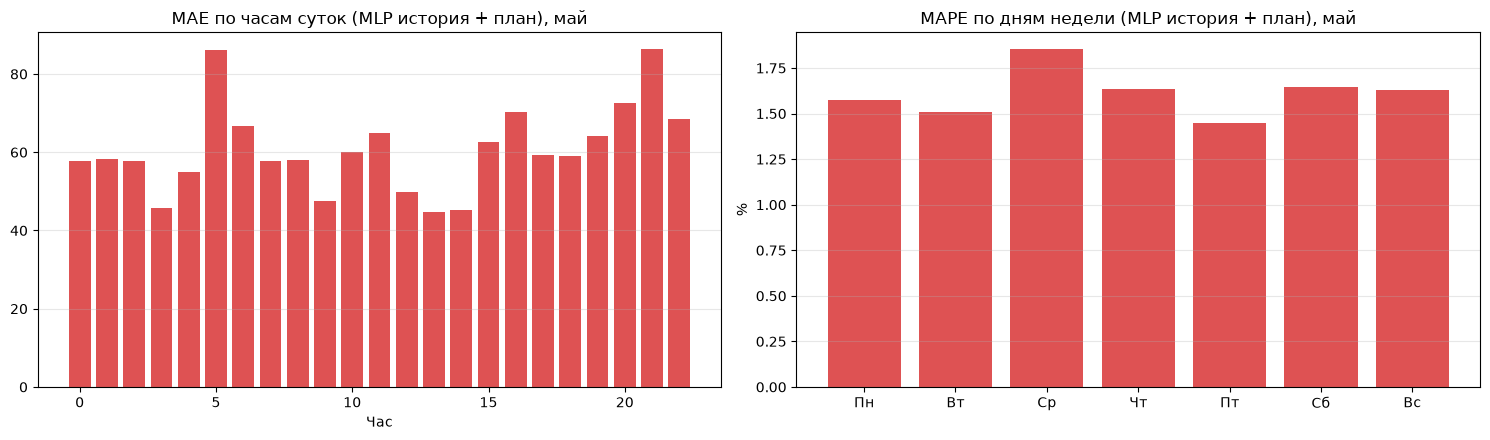

In [16]:
# Рис. 6. Ошибка по часам суток и по дням недели (май)
hour_mae = np.abs(yt - p_hp).mean(axis=0)
dow = may_days.dayofweek
dow_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
dow_mape = [daily_mape[dow == i].mean() if (dow == i).any() else np.nan for i in range(7)]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(range(23), hour_mae, color='tab:red', alpha=.8)
ax[0].set_title('MAE по часам суток (MLP история + план), май'); ax[0].set_xlabel('Час'); ax[0].grid(axis='y', alpha=.3)
ax[1].bar(dow_names, dow_mape, color='tab:red', alpha=.8)
ax[1].set_title('MAPE по дням недели (MLP история + план), май'); ax[1].set_ylabel('%'); ax[1].grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig('figures_may/06_may_errors.png', dpi=200); plt.show()

In [17]:
# Итоговая сводка для слайда
best_model = 'MLP (история + план)'
print(f'Май {YEAR}, прогноз на сутки вперёд, {best_model}:')
print(f"  MAE  = {may_table.loc[best_model, 'MAE']:.1f}")
print(f"  RMSE = {may_table.loc[best_model, 'RMSE']:.1f}")
print(f"  MAPE = {may_table.loc[best_model, 'MAPE, %']:.2f}%")
print(f"  R²   = {may_table.loc[best_model, 'R2']:.3f}")

Май 2026, прогноз на сутки вперёд, MLP (история + план):
  MAE  = 60.8
  RMSE = 76.2
  MAPE = 1.61%
  R²   = 0.866
